# Figure S7: AMOC strength in density space and depth space, 8xCO2

Maximum of the streamfunction north of 45N, in the Atlantic region. The density-space record is cut at the end of the
depth-space record on the x axis.

Inputs: `PSI_SIGMA1_POP_MOC_8x.nc`, `amoc_ann_CESM104_abrupt8x_5100.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
# The density-space file is chunked by year, so it is read in 500-year blocks
psi = xr.open_dataset(common.data_path('PSI_SIGMA1_POP_MOC_8x.nc'), chunks={'year': 500})
strength_density = psi.MOC.isel(transport_reg=1, drop=True).sel(lat_aux_grid=slice(45, None)).load().max(dim=['lat_aux_grid', 'sigma'])
years_density = strength_density.year.values - common.BRANCH_YEAR

strength_depth = common.amoc_strength('amoc_ann_CESM104_abrupt8x_5100.nc')
print(f'density space mean {float(strength_density.mean()):.2f} Sv; depth space mean {float(strength_depth.mean()):.2f} Sv')

density space mean 9.54 Sv; depth space mean 8.92 Sv


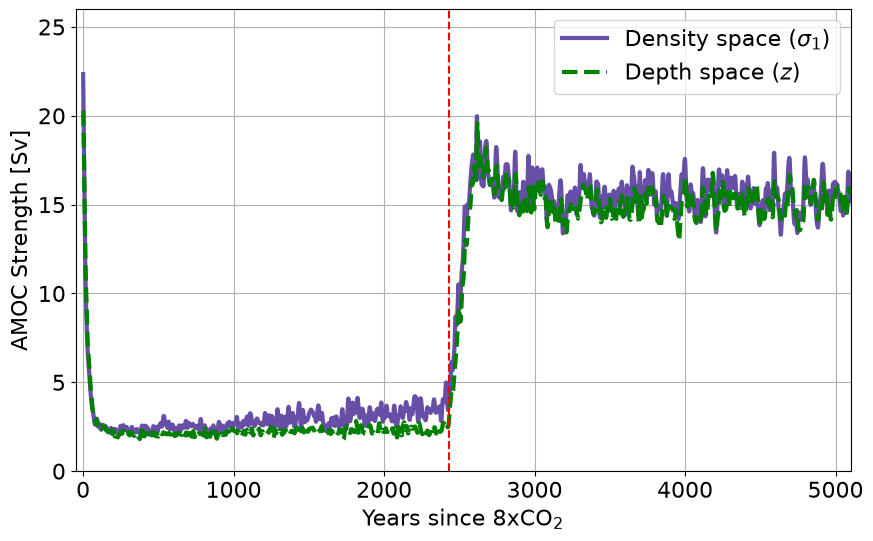

In [3]:
plt.subplots(figsize=(10, 6))
plt.plot(years_density, common.butterworth_lowpass(strength_density.values), color='#674ea7', linewidth=3,
         label='Density space ($\\sigma_1$)')
plt.plot(strength_depth.time.values, common.butterworth_lowpass(strength_depth.values), color='Green', linewidth=3,
         linestyle='--', label='Depth space ($z$)')
plt.axvline(common.RECOVERY_YEAR, color='red', linestyle='--')
plt.legend()
plt.grid()
plt.ylabel('AMOC Strength [Sv]')
plt.xlabel('Years since 8xCO$_2$')
plt.xlim([-common.X_START_PAD, 5100])
plt.ylim([0, 26])
for extension in ('png', 'pdf'):
    plt.savefig(common.figure_path(f'figS7_amoc_density_vs_depth.{extension}'), dpi=300, bbox_inches='tight', facecolor='white')
plt.show()